In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load
import pandas as pd
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [6]:
cd=pd.read_csv("/kaggle/input/108-crash-data-report/1.08_Crash_Data_Report_(detail).csv")
cd

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/108-crash-data-report/1.08_Crash_Data_Report_(detail).csv'

In [ ]:
cd.columns

Index(['X', 'Y', 'OBJECTID', 'Incidentid', 'DateTime', 'Year', 'StreetName',
       'CrossStreet', 'Distance', 'JunctionRelation', 'Totalinjuries',
       'Totalfatalities', 'Injuryseverity', 'Collisionmanner',
       'Lightcondition', 'Weather', 'SurfaceCondition', 'Unittype_One',
       'Age_Drv1', 'Gender_Drv1', 'Traveldirection_One', 'Unitaction_One',
       'Violation1_Drv1', 'AlcoholUse_Drv1', 'DrugUse_Drv1', 'Unittype_Two',
       'Age_Drv2', 'Gender_Drv2', 'Traveldirection_Two', 'Unitaction_Two',
       'Violation1_Drv2', 'AlcoholUse_Drv2', 'DrugUse_Drv2', 'Latitude',
       'Longitude'],
      dtype='object')

# 1.Handle missing values:

Check for missing values in each column: 

In [4]:
cd.isnull().sum()


X                       139
Y                       139
OBJECTID                  0
Incidentid                0
DateTime                  0
Year                      0
StreetName               19
CrossStreet              42
Distance                  1
JunctionRelation          1
Totalinjuries             1
Totalfatalities           1
Injuryseverity            1
Collisionmanner           1
Lightcondition            1
Weather                   1
SurfaceCondition          1
Unittype_One              1
Age_Drv1                 39
Gender_Drv1             825
Traveldirection_One       1
Unitaction_One            1
Violation1_Drv1          39
AlcoholUse_Drv1          39
DrugUse_Drv1             39
Unittype_Two           2837
Age_Drv2               4018
Gender_Drv2            4111
Traveldirection_Two    2837
Unitaction_Two         2837
Violation1_Drv2        4018
AlcoholUse_Drv2        4018
DrugUse_Drv2           4018
Latitude                139
Longitude               139
dtype: int64

check for column types:

In [5]:
cd.dtypes

X                      float64
Y                      float64
OBJECTID                 int64
Incidentid               int64
DateTime                object
Year                     int64
StreetName              object
CrossStreet             object
Distance               float64
JunctionRelation        object
Totalinjuries          float64
Totalfatalities        float64
Injuryseverity          object
Collisionmanner         object
Lightcondition          object
Weather                 object
SurfaceCondition        object
Unittype_One            object
Age_Drv1               float64
Gender_Drv1             object
Traveldirection_One     object
Unitaction_One          object
Violation1_Drv1         object
AlcoholUse_Drv1         object
DrugUse_Drv1            object
Unittype_Two            object
Age_Drv2               float64
Gender_Drv2             object
Traveldirection_Two     object
Unitaction_Two          object
Violation1_Drv2         object
AlcoholUse_Drv2         object
DrugUse_

In [6]:
cd['Distance'].fillna(cd['Distance'].mean(), inplace=True)
cd['Totalinjuries'].fillna(cd['Totalinjuries'].mean(), inplace=True)
cd['Totalfatalities'].fillna(cd['Totalfatalities'].mean(), inplace=True)


In [7]:
cd.columns

Index(['X', 'Y', 'OBJECTID', 'Incidentid', 'DateTime', 'Year', 'StreetName',
       'CrossStreet', 'Distance', 'JunctionRelation', 'Totalinjuries',
       'Totalfatalities', 'Injuryseverity', 'Collisionmanner',
       'Lightcondition', 'Weather', 'SurfaceCondition', 'Unittype_One',
       'Age_Drv1', 'Gender_Drv1', 'Traveldirection_One', 'Unitaction_One',
       'Violation1_Drv1', 'AlcoholUse_Drv1', 'DrugUse_Drv1', 'Unittype_Two',
       'Age_Drv2', 'Gender_Drv2', 'Traveldirection_Two', 'Unitaction_Two',
       'Violation1_Drv2', 'AlcoholUse_Drv2', 'DrugUse_Drv2', 'Latitude',
       'Longitude'],
      dtype='object')

In [8]:
columns_to_backfill = ['StreetName', 'CrossStreet', 'JunctionRelation', 'Injuryseverity', 'Collisionmanner', 'Lightcondition', 'Weather', 'SurfaceCondition', 'Unittype_One', 'Age_Drv1', 'Gender_Drv1', 'Traveldirection_One', 'Unitaction_One', 'Violation1_Drv1', 'AlcoholUse_Drv1', 'DrugUse_Drv1', 'Unittype_Two', 'Age_Drv2', 'Gender_Drv2', 'Traveldirection_Two', 'Unitaction_Two', 'Violation1_Drv2', 'AlcoholUse_Drv2', 'DrugUse_Drv2', 'Latitude', 'Longitude']

# Perform backfilling on the specified columns
cd[columns_to_backfill] = cd[columns_to_backfill].fillna(method='bfill')


Remove irrelevent columns:

In [9]:
columns_to_remove = ['X','Y','OBJECTID', 'Incidentid']
cd.drop(columns=columns_to_remove,inplace=True)


Now here data is clean :

In [10]:
cd.isnull().sum()

DateTime               0
Year                   0
StreetName             0
CrossStreet            0
Distance               0
JunctionRelation       0
Totalinjuries          0
Totalfatalities        0
Injuryseverity         0
Collisionmanner        0
Lightcondition         0
Weather                0
SurfaceCondition       0
Unittype_One           0
Age_Drv1               0
Gender_Drv1            0
Traveldirection_One    0
Unitaction_One         0
Violation1_Drv1        0
AlcoholUse_Drv1        0
DrugUse_Drv1           0
Unittype_Two           0
Age_Drv2               0
Gender_Drv2            0
Traveldirection_Two    0
Unitaction_Two         0
Violation1_Drv2        0
AlcoholUse_Drv2        0
DrugUse_Drv2           0
Latitude               0
Longitude              0
dtype: int64

In [11]:
cd.columns

Index(['DateTime', 'Year', 'StreetName', 'CrossStreet', 'Distance',
       'JunctionRelation', 'Totalinjuries', 'Totalfatalities',
       'Injuryseverity', 'Collisionmanner', 'Lightcondition', 'Weather',
       'SurfaceCondition', 'Unittype_One', 'Age_Drv1', 'Gender_Drv1',
       'Traveldirection_One', 'Unitaction_One', 'Violation1_Drv1',
       'AlcoholUse_Drv1', 'DrugUse_Drv1', 'Unittype_Two', 'Age_Drv2',
       'Gender_Drv2', 'Traveldirection_Two', 'Unitaction_Two',
       'Violation1_Drv2', 'AlcoholUse_Drv2', 'DrugUse_Drv2', 'Latitude',
       'Longitude'],
      dtype='object')

# Exploratory Data Analysis:
To perform exploratory data analysis on the given columns, you can explore various aspects of the data to gain insights and understand patterns or relationships.

# 1.Summary statistics: 
Calculate basic summary statistics for numerical columns like 'Distance', 'Totalinjuries', and 'Totalfatalities'. You can use functions such as describe() to get an overview of the data distribution.

In [12]:
cd.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Year,43998.0,2016.421928,2.809347,2012.000000,2014.000000,2016.000000,2019.000000,2022.000000
Distance,43998.0,4.387425,271.438285,-5280.000000,-70.224000,0.000000,79.800000,5377.152000
Totalinjuries,43998.0,0.458986,0.808944,0.000000,0.000000,0.000000,1.000000,9.000000
Totalfatalities,43998.0,0.003000,0.057527,0.000000,0.000000,0.000000,0.000000,3.000000
Age_Drv1,43998.0,46.376153,40.901574,2.000000,22.000000,32.000000,53.000000,255.000000
Age_Drv2,43998.0,39.314628,22.309722,2.000000,24.000000,34.000000,50.000000,255.000000
Latitude,43998.0,33.397829,0.028682,33.319857,33.378258,33.407328,33.421931,33.458490
Longitude,43998.0,-111.932748,0.024024,-111.978469,-111.952189,-111.928605,-111.911245,-111.877419


# 2.Data distribution: 
Visualize the distributions of numerical columns using histograms, box plots, or violin plots. This can provide insights into the spread and skewness of the data.

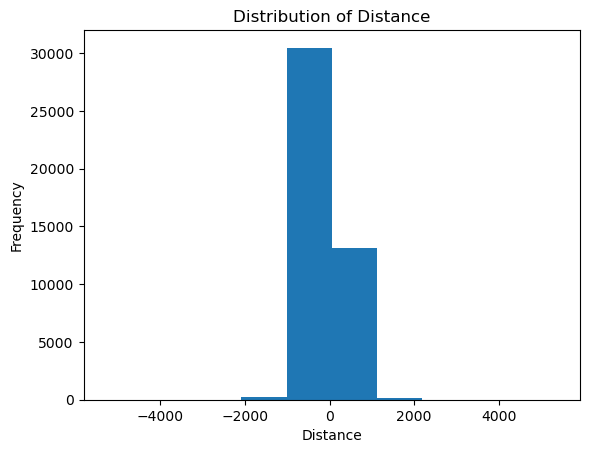

In [13]:
import matplotlib.pyplot as plt

# Histogram
plt.hist(cd['Distance'], bins=10)
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.title('Distribution of Distance')
plt.show()


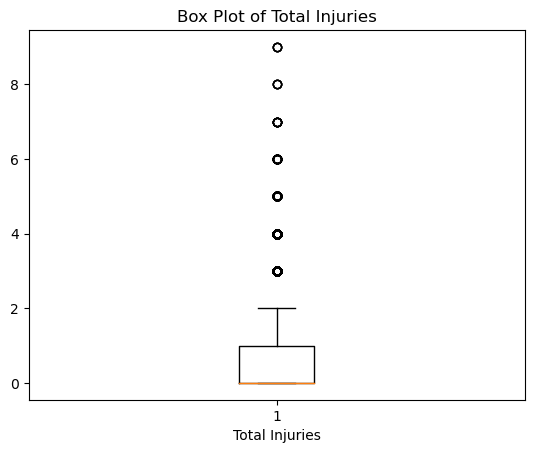

In [14]:
# Box plot
plt.boxplot(cd['Totalinjuries'])
plt.xlabel('Total Injuries')
plt.title('Box Plot of Total Injuries')
plt.show()


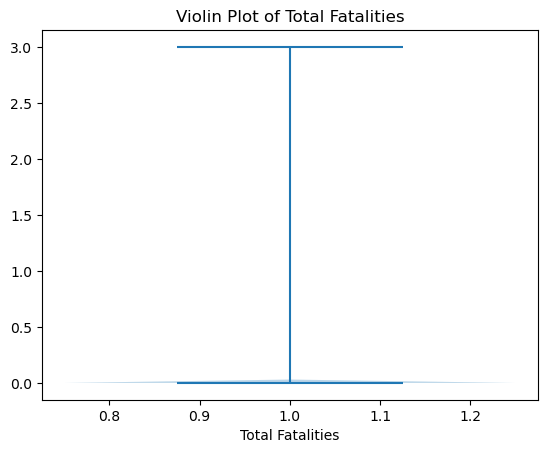

In [15]:
# Violin plot
plt.violinplot(cd['Totalfatalities'])
plt.xlabel('Total Fatalities')
plt.title('Violin Plot of Total Fatalities')
plt.show()


# 3.Categorical variables: 
For categorical columns like 'Injuryseverity', 'Collisionmanner', 'Lightcondition', etc., you can generate bar plots or count plots to analyze the frequency or proportion of each category.

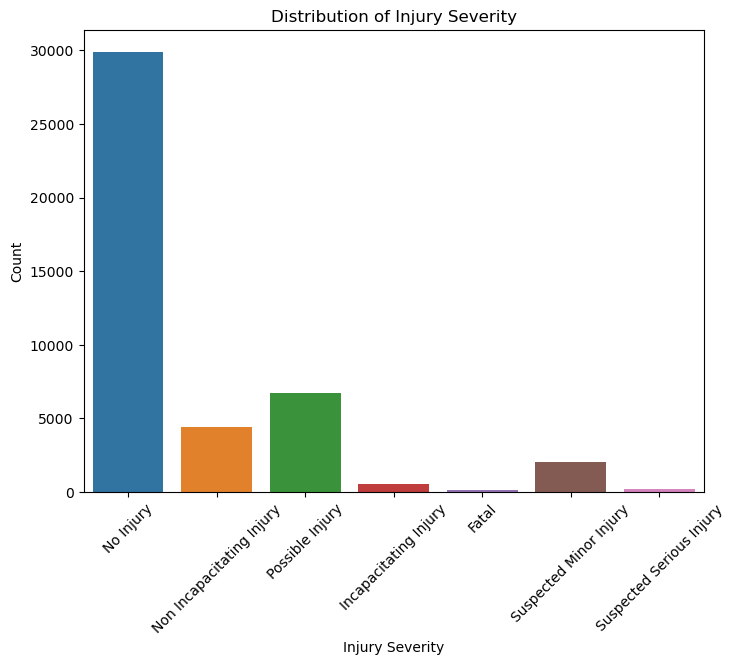

In [16]:
import seaborn as sns

# Bar plot for 'Injuryseverity'
plt.figure(figsize=(8, 6))
sns.countplot(x='Injuryseverity', data=cd)
plt.xlabel('Injury Severity')
plt.ylabel('Count')
plt.title('Distribution of Injury Severity')
plt.xticks(rotation=45)
plt.show()


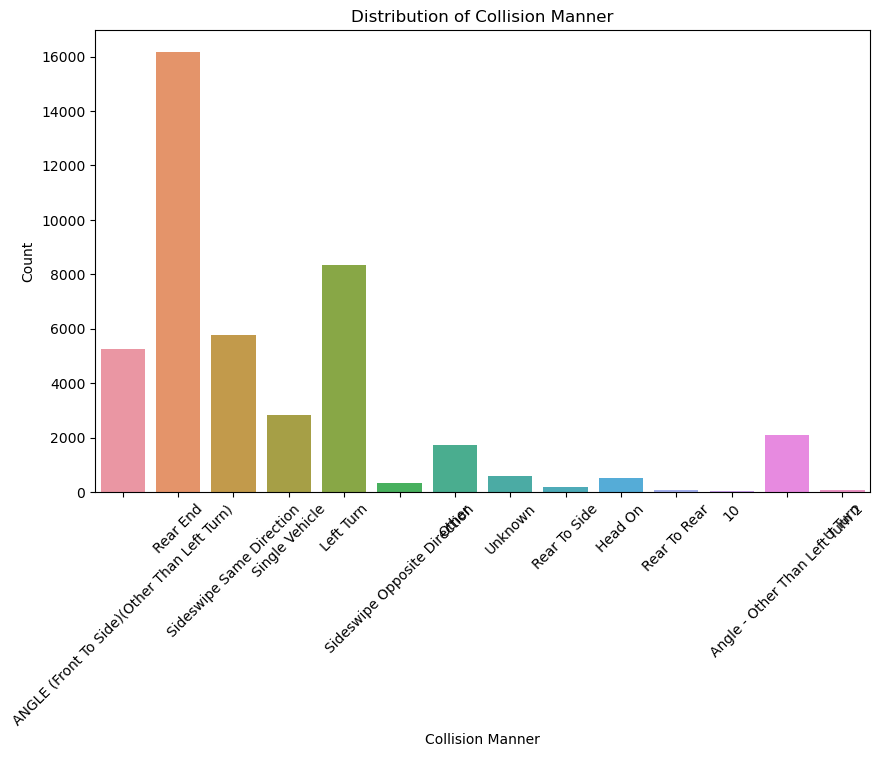

In [17]:
# Bar plot for 'Collisionmanner'
plt.figure(figsize=(10, 6))
sns.countplot(x='Collisionmanner', data=cd)
plt.xlabel('Collision Manner')
plt.ylabel('Count')
plt.title('Distribution of Collision Manner')
plt.xticks(rotation=45)
plt.show()


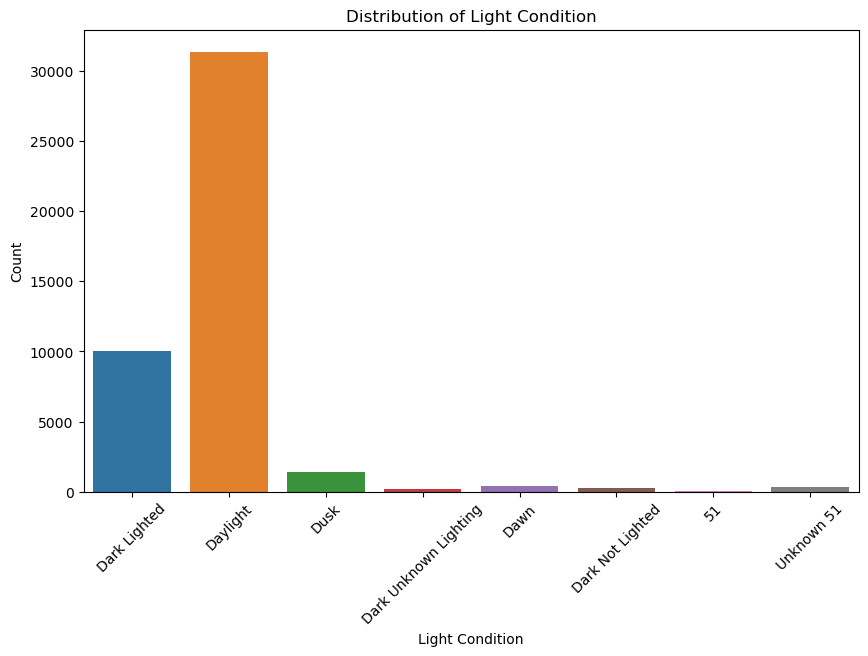

In [18]:
# Bar plot for 'Lightcondition'
plt.figure(figsize=(10, 6))
sns.countplot(x='Lightcondition', data=cd)
plt.xlabel('Light Condition')
plt.ylabel('Count')
plt.title('Distribution of Light Condition')
plt.xticks(rotation=45)
plt.show()


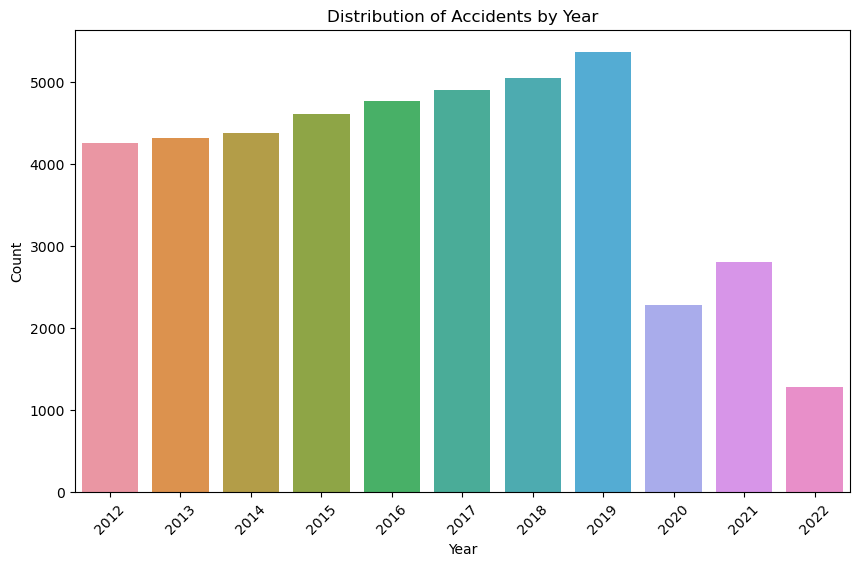

In [19]:
# Bar plot for 'Year'
plt.figure(figsize=(10, 6))
sns.countplot(x='Year', data=cd)
plt.xlabel('Year')
plt.ylabel('Count')
plt.title('Distribution of Accidents by Year')
plt.xticks(rotation=45)
plt.show()

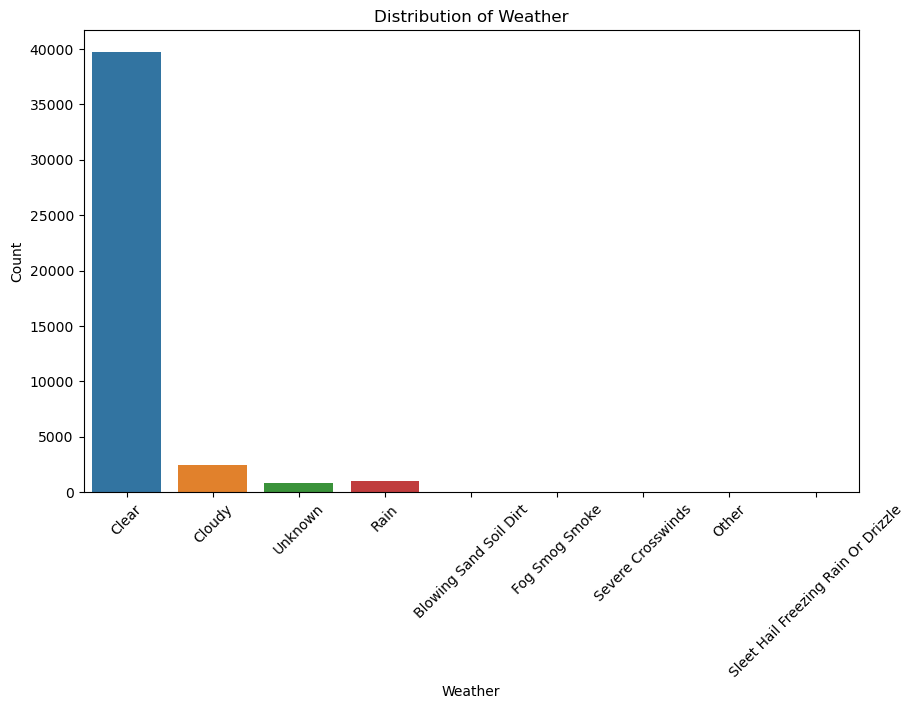

In [20]:
# Bar plot for 'Weather'
plt.figure(figsize=(10, 6))
sns.countplot(x='Weather', data=cd)
plt.xlabel('Weather')
plt.ylabel('Count')
plt.title('Distribution of Weather')
plt.xticks(rotation=45)
plt.show()

# 4.Correlation analysis: 
Calculate the correlation between numerical variables using methods such as Pearson correlation or Spearman correlation. This can help identify any linear or monotonic relationships between variables.

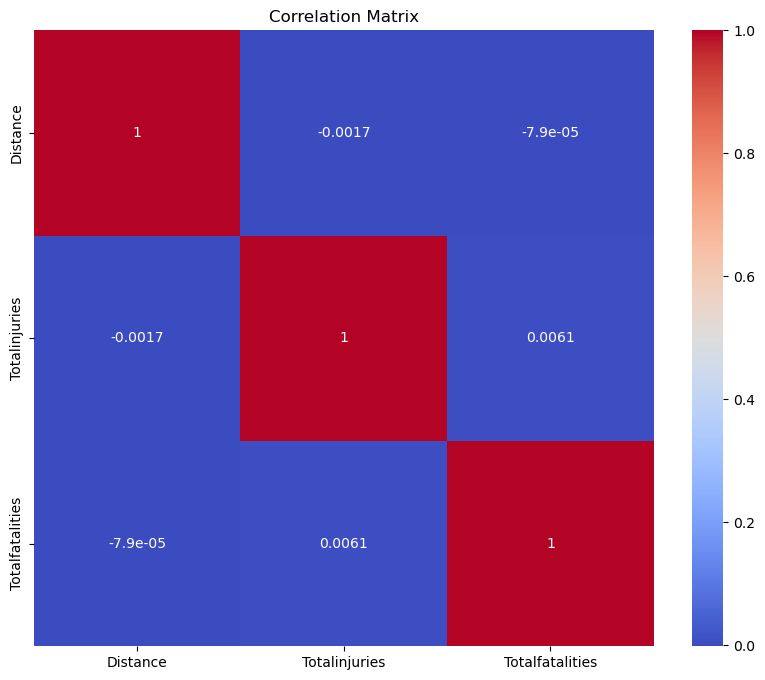

In [21]:
correlation_matrix = cd[['Distance', 'Totalinjuries', 'Totalfatalities']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


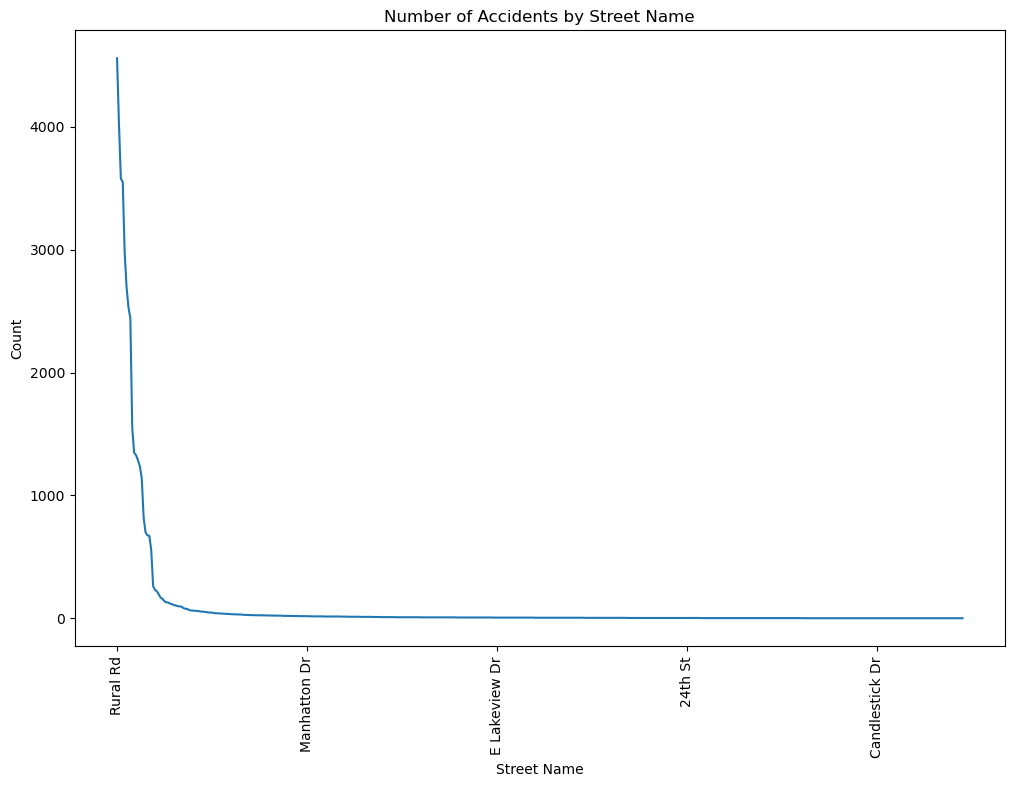

In [22]:
plt.figure(figsize=(12, 8))
street_counts = cd['StreetName'].value_counts().sort_values(ascending=False)
street_counts.plot(kind='line')
plt.xlabel('Street Name')
plt.ylabel('Count')
plt.title('Number of Accidents by Street Name')
plt.xticks(rotation=90)
plt.show()


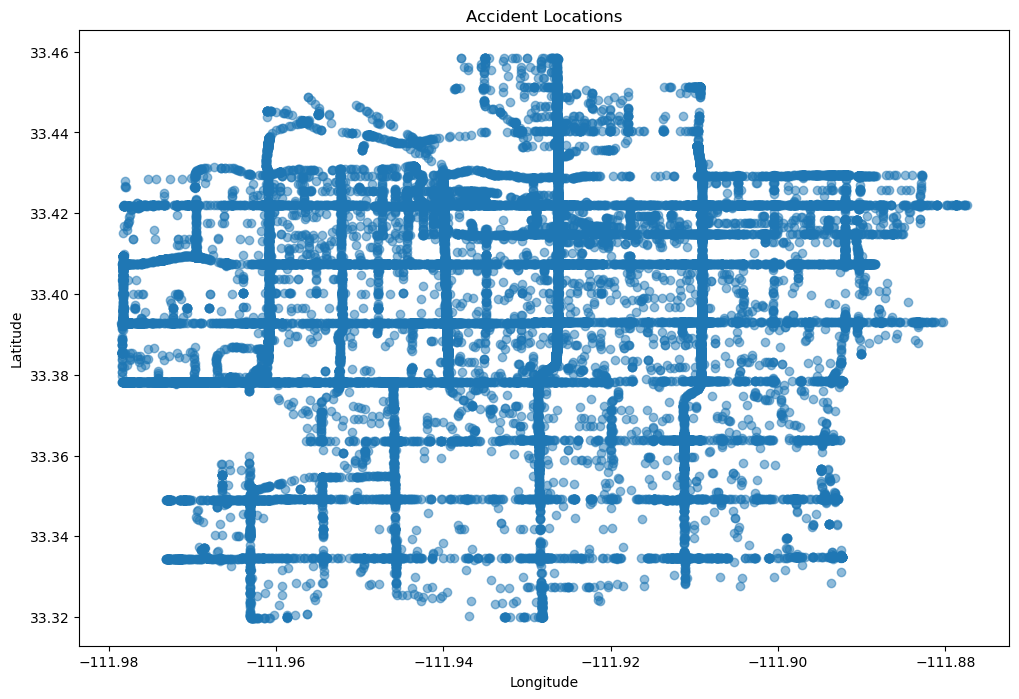

In [23]:
#Scatter plot
plt.figure(figsize=(12, 8))
plt.scatter(x=cd['Longitude'], y=cd['Latitude'], alpha=0.5)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Accident Locations')
plt.show()


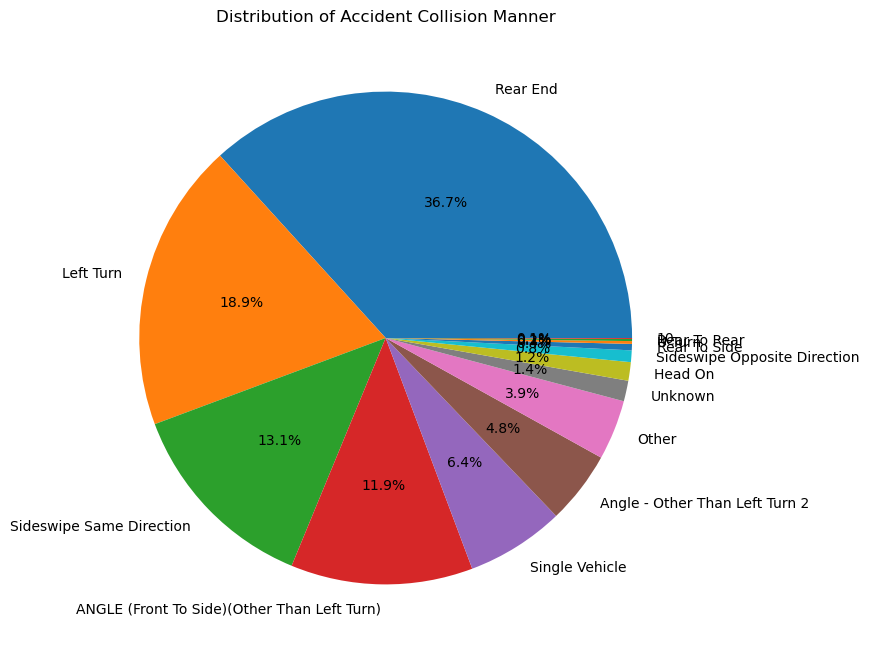

In [24]:
#Pie chart
plt.figure(figsize=(10, 8))
collision_counts = cd['Collisionmanner'].value_counts()
plt.pie(collision_counts, labels=collision_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Accident Collision Manner')
plt.show()


# 5.Time analysis: 
The 'Year' column represents the year of the accident, you can analyze the trends and patterns over time using line plots or bar plots.

# ****And Also:-

# Long-term Trends: 
Analyzing the long-term trends in accident rates over several years can reveal broader patterns and provide insights into the effectiveness of long-term road safety strategies. It can help identify whether accident rates have been consistently declining, indicating sustained improvements in road safety, or if there are any periods of stagnation or regression.

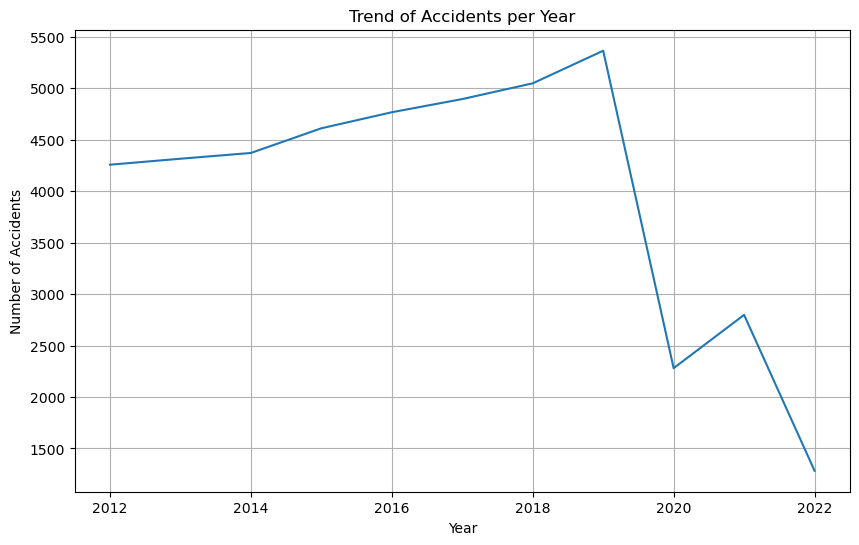

In [25]:
# Count the number of accidents per year
yearly_counts = cd['Year'].value_counts().sort_index()

# Create a line plot
plt.figure(figsize=(10, 6))
yearly_counts.plot(kind='line')
plt.xlabel('Year')
plt.ylabel('Number of Accidents')
plt.title('Trend of Accidents per Year')
plt.grid(True)
plt.show()


# 6.Cross-tabulation: 
Create cross-tabulations or contingency tables to analyze the relationship between different categorical variables. This can help identify any dependencies or associations between variables.

To create cross-tabulations or contingency tables to analyze the relationship between different categorical variables, you can use the pd.crosstab() function in pandas

In [26]:
# Create a cross-tabulation with row and column totals
cross_tab = pd.crosstab(cd['Injuryseverity'], cd['Collisionmanner'], margins=True)

# Display the cross-tabulation
print(cross_tab)


Collisionmanner            10  ANGLE (Front To Side)(Other Than Left Turn)  \
Injuryseverity                                                               
Fatal                       0                                           11   
Incapacitating Injury       0                                          136   
No Injury                  20                                         3189   
Non Incapacitating Injury   4                                         1003   
Possible Injury             3                                          916   
Suspected Minor Injury      0                                            0   
Suspected Serious Injury    0                                            0   
All                        27                                         5255   

Collisionmanner            Angle - Other Than Left Turn 2  Head On  Left Turn  \
Injuryseverity                                                                  
Fatal                                                   4

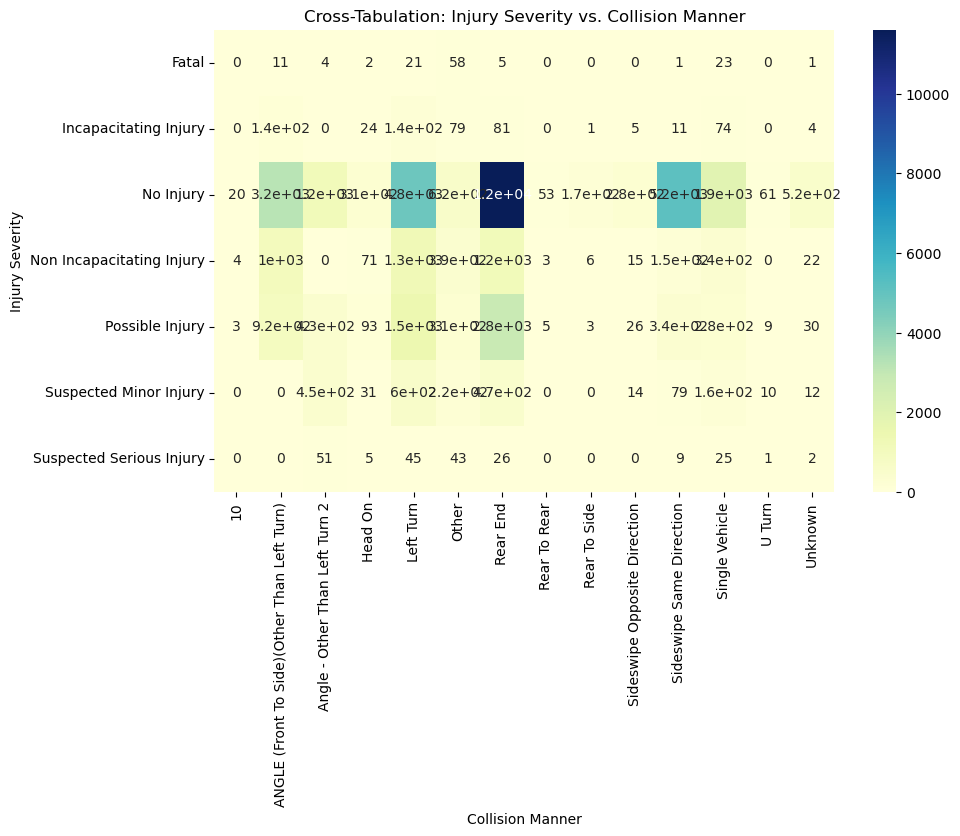

In [27]:
# Create a cross-tabulation and plot it as a heatmap
cross_tab = pd.crosstab(cd['Injuryseverity'], cd['Collisionmanner'])
plt.figure(figsize=(10, 6))
sns.heatmap(cross_tab, annot=True, cmap='YlGnBu')
plt.xlabel('Collision Manner')
plt.ylabel('Injury Severity')
plt.title('Cross-Tabulation: Injury Severity vs. Collision Manner')
plt.show()


# 7.Seasonal Patterns: 
Analyzing the number of accidents by season or month can help identify any seasonal patterns or variations in accident frequency. For example, there may be higher accident rates during winter due to adverse weather conditions or during holiday seasons when traffic volume is high. Understanding these seasonal patterns can guide the implementation of targeted safety measures during specific periods.

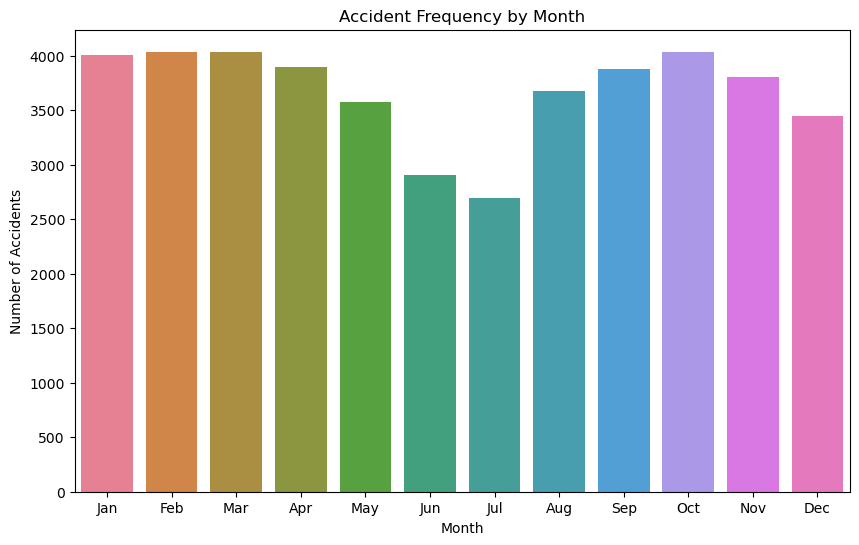

In [28]:
import seaborn as sns

# Extract the month from the DateTime column
cd['Month'] = pd.to_datetime(cd['DateTime']).dt.month

# Group the data by month and calculate the count of accidents
monthly_accidents = cd['Month'].value_counts().sort_index()

# Define the labels for each month
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Define a color palette for the months
colors = sns.color_palette('husl', len(monthly_accidents))

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(x=monthly_accidents.index, y=monthly_accidents.values, palette=colors)
plt.xlabel('Month')
plt.ylabel('Number of Accidents')
plt.title('Accident Frequency by Month')
plt.xticks(ticks=range(12), labels=month_labels)
plt.show()


# 8.Outliers and Anomalies: 
Examining any outliers or anomalies in the yearly accident data can help identify unusual patterns or events that require further investigation. For instance, a significant increase in accidents in a particular year may be attributed to factors like changes in population, road construction, or shifts in traffic patterns. Understanding these anomalies can inform targeted interventions and preventive measures.

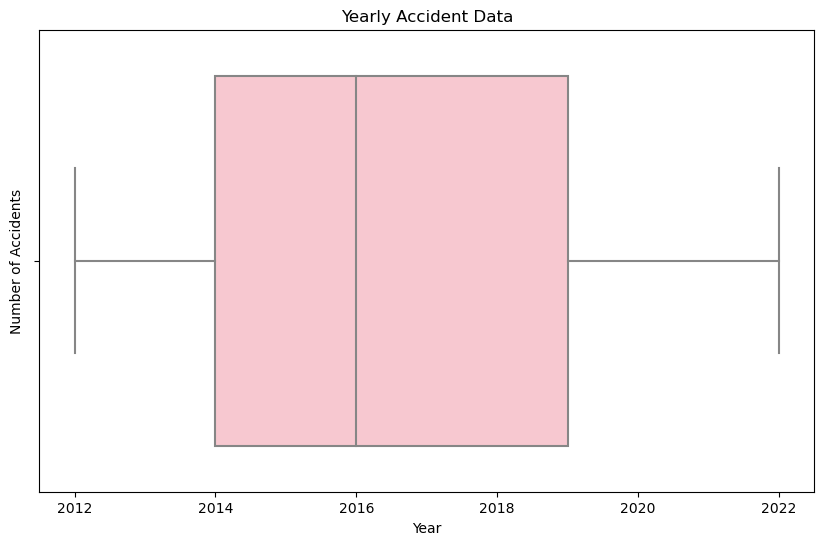

In [29]:
# Create the box plot
plt.figure(figsize=(10, 6))
sns.boxplot(x=cd['Year'], color='pink')
plt.xlabel('Year')
plt.ylabel('Number of Accidents')
plt.title('Yearly Accident Data')
plt.show()


# 9.StreetName and CrossStreet: 
These columns provide information about the location of the accidents. By analyzing the frequency of accidents on different streets and the intersections between streets, we can identify high-risk areas or intersections that require attention from a safety perspective.

Analyzing the frequency of accidents on different streets and at intersections can provide valuable insights into high-risk areas and intersections that require attention from a safety perspective. By examining the data related to 'StreetName' and 'CrossStreet', we can identify patterns and prioritize efforts to improve road safety.

# Heatmap: 
Generate a heatmap to visualize the frequency of accidents at different intersections. This will provide an overview of the areas with a higher concentration of accidents. The seaborn library's heatmap() function can be used for this purpose.

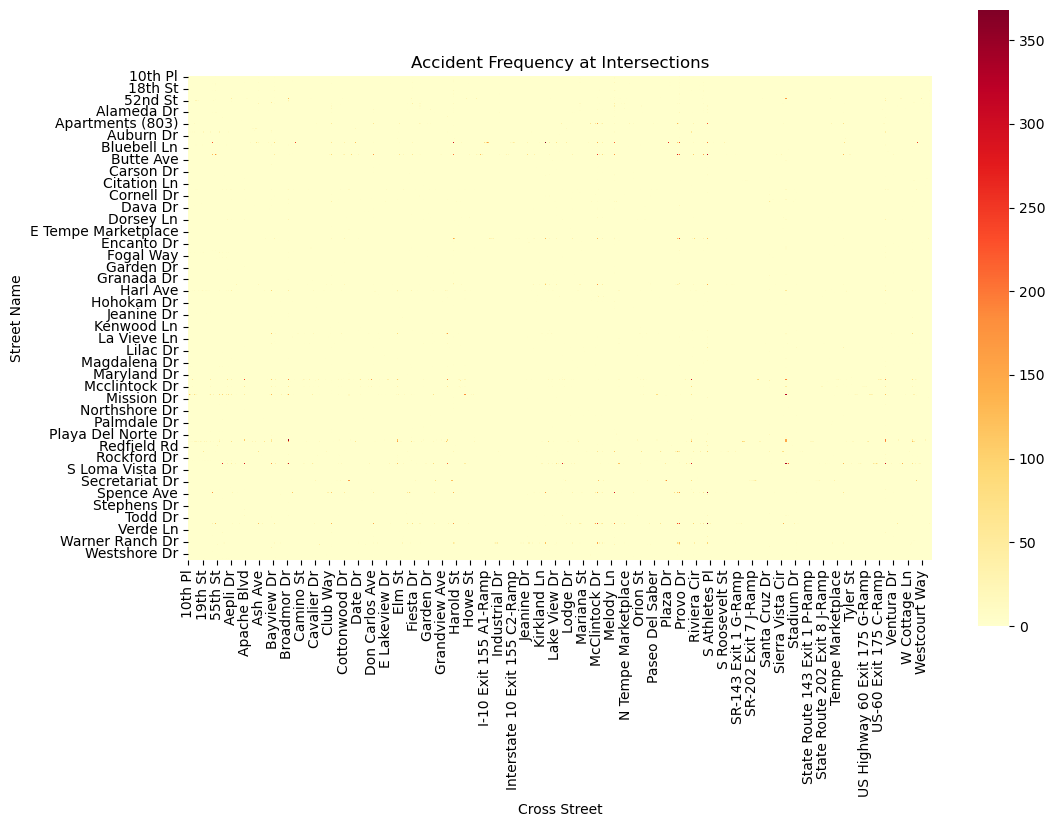

In [30]:
# Create a cross-tabulation of accidents by street name and cross street
intersection_table = pd.crosstab(cd['StreetName'], cd['CrossStreet'])

# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(intersection_table, cmap='YlOrRd', square=True)
plt.xlabel('Cross Street')
plt.ylabel('Street Name')
plt.title('Accident Frequency at Intersections')
plt.show()

# 10.Distance: 
The 'Distance' column represents the distance related to the accidents. Analyzing the distribution and summary statistics of this variable can provide insights into the typical distance involved in accidents. This information can be useful for understanding the severity of accidents occurring at different distances.

# A.Histogram: 
Create a histogram to visualize the distribution of distances. This will show the frequency of accidents at different distance intervals. You can use the matplotlib library's hist() function or seaborn's distplot() function.

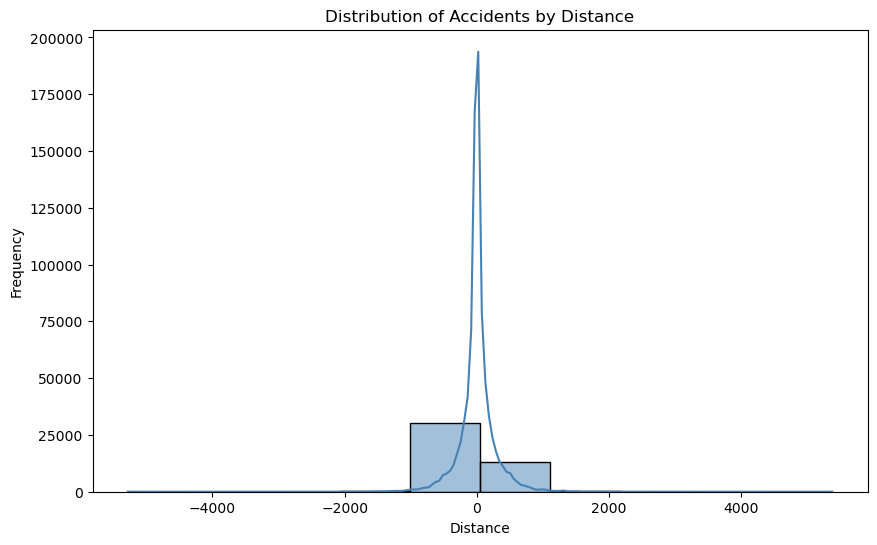

In [31]:
# Plot the histogram
plt.figure(figsize=(10, 6))
sns.histplot(data=cd, x='Distance', bins=10, kde=True, color='steelblue')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.title('Distribution of Accidents by Distance')
plt.show()

# B.Box plot: 
Construct a box plot to visualize the distribution of distances, including information about outliers and the spread of the data. This can help identify any extreme distances or variations in the dataset. Seaborn's boxplot() function or matplotlib's boxplot() function can be used for this purpose.

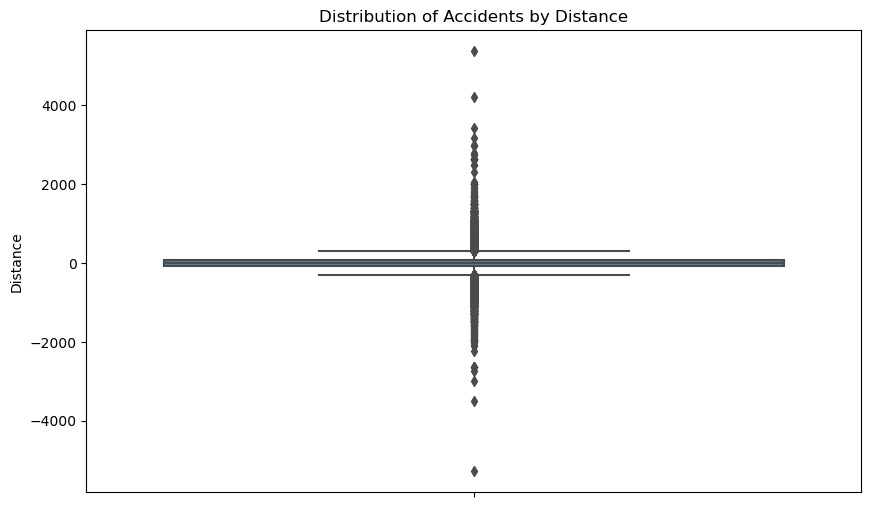

In [32]:
# Plot the box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=cd, y='Distance', color='steelblue')
plt.ylabel('Distance')
plt.title('Distribution of Accidents by Distance')
plt.show()

# 11.JunctionRelation: 
This column provides information about the relation of accidents to junctions. Analyzing the distribution of different junction relations can help identify any patterns or correlations between accidents and the presence of junctions. This insight can assist in improving the design and safety of junctions.

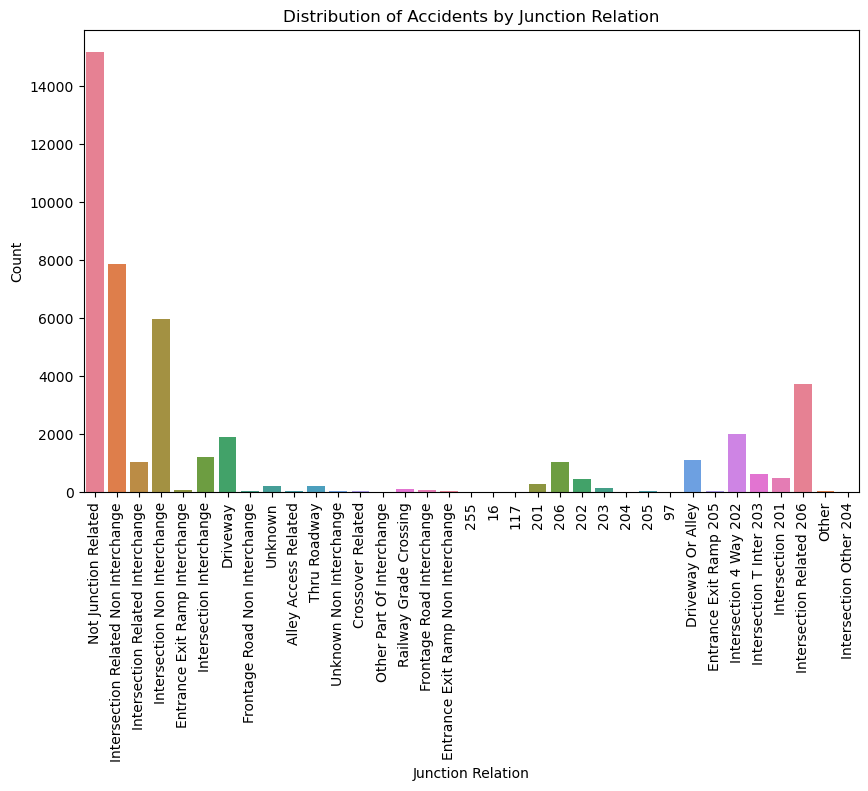

In [33]:
colors = sns.color_palette('husl', len('JunctionRelation'))
# Create the count plot
plt.figure(figsize=(10, 6))

sns.countplot(data=cd, x='JunctionRelation', palette=colors)
plt.xlabel('Junction Relation')
plt.ylabel('Count')
plt.title('Distribution of Accidents by Junction Relation')
plt.xticks(rotation=90)
plt.show()




# 12.Totalinjuries and Totalfatalities: 
These columns represent the total number of injuries and fatalities in each accident. Analyzing the distribution and summary statistics of these variables can provide insights into the severity of accidents and help identify any trends or patterns related to injuries and fatalities.

# A.Histogram: 
Create a histogram to visualize the distribution of 'Totalinjuries' and 'Totalfatalities'. This will show the frequency of accidents with different numbers of injuries and fatalities.

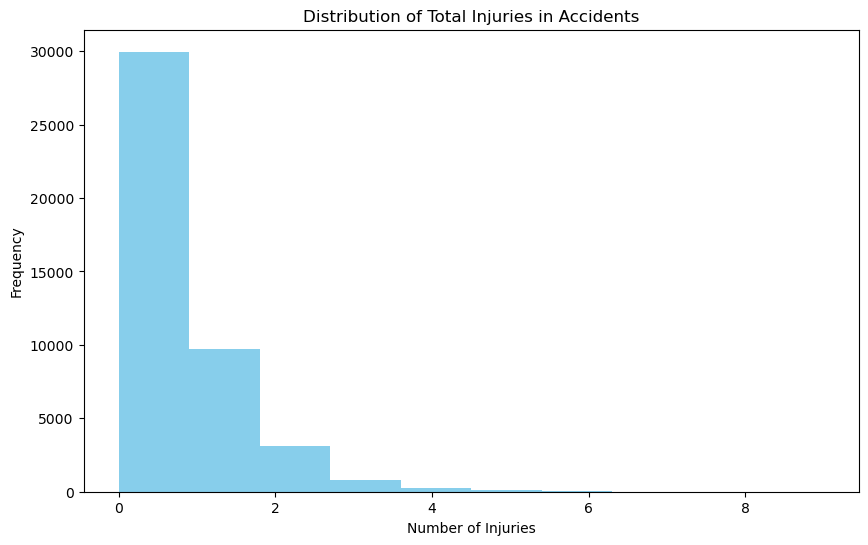

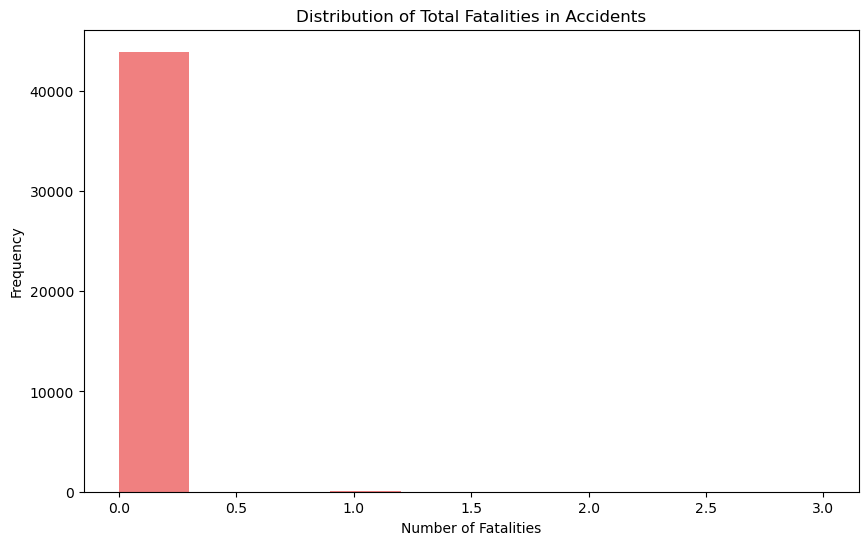

In [34]:
# Plot histogram for 'Totalinjuries'
plt.figure(figsize=(10, 6))
plt.hist(cd['Totalinjuries'], bins=10, color='skyblue')
plt.xlabel('Number of Injuries')
plt.ylabel('Frequency')
plt.title('Distribution of Total Injuries in Accidents')
plt.show()

# Plot histogram for 'Totalfatalities'
plt.figure(figsize=(10, 6))
plt.hist(cd['Totalfatalities'], bins=10, color='lightcoral')
plt.xlabel('Number of Fatalities')
plt.ylabel('Frequency')
plt.title('Distribution of Total Fatalities in Accidents')
plt.show()

# B.Box plot: 
Construct a box plot to visualize the distribution of 'Totalinjuries' and 'Totalfatalities', including information about outliers and the spread of the data. This can help identify any extreme values or variations in the dataset.

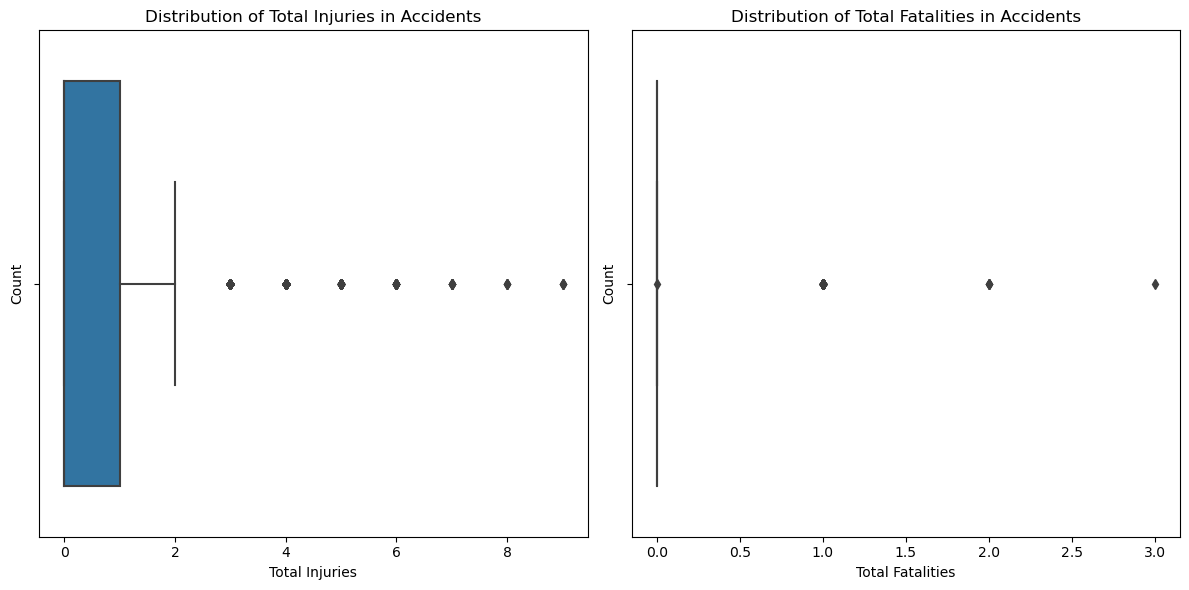

In [35]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Box plot for 'Totalinjuries'
sns.boxplot(x=cd['Totalinjuries'], ax=axes[0])
axes[0].set_xlabel('Total Injuries')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Total Injuries in Accidents')

# Box plot for 'Totalfatalities'
sns.boxplot(x=cd['Totalfatalities'], ax=axes[1])
axes[1].set_xlabel('Total Fatalities')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of Total Fatalities in Accidents')

# Adjust the layout and display the plot
plt.tight_layout()
plt.show()





# 13.Unittype_One and Unittype_Two: 
These columns provide information about the types of units involved in accidents. Analyzing the frequencies of different unit types can help identify the most common types of vehicles or units involved in accidents. This insight can assist in targeting safety measures for specific vehicle types or identifying potential vehicle-related issues.

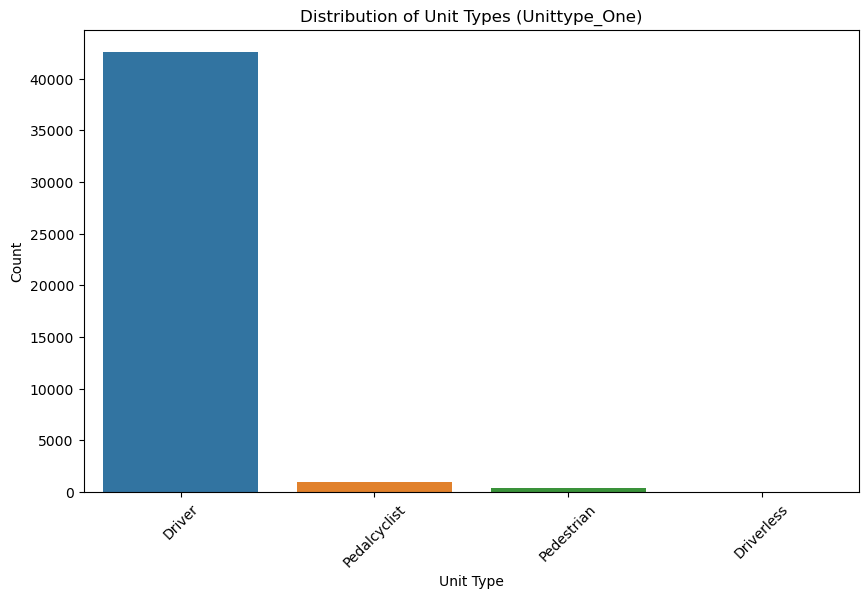

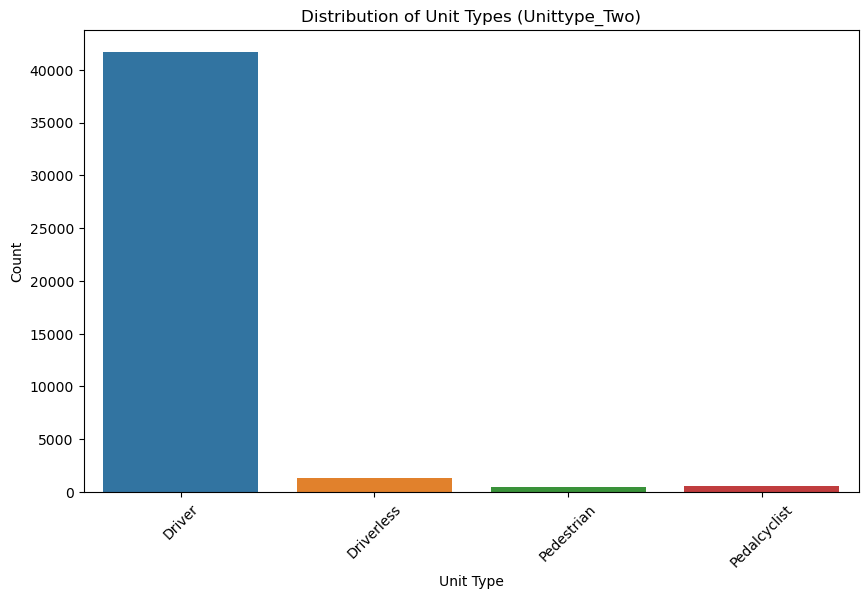

In [36]:
# Create a count plot for 'Unittype_One'
plt.figure(figsize=(10, 6))
sns.countplot(x='Unittype_One', data=cd)
plt.xlabel('Unit Type')
plt.ylabel('Count')
plt.title('Distribution of Unit Types (Unittype_One)')
plt.xticks(rotation=45)
plt.show()

# Create a count plot for 'Unittype_Two'
plt.figure(figsize=(10, 6))
sns.countplot(x='Unittype_Two', data=cd)
plt.xlabel('Unit Type')
plt.ylabel('Count')
plt.title('Distribution of Unit Types (Unittype_Two)')
plt.xticks(rotation=45)
plt.show()


In [37]:
# Define the conditions for filtering
condition1 = (cd['Age_Drv1'] > 50)
condition2 = (cd['Age_Drv2'] > 50)

# Apply the conditions to filter the dataset
filtered_dataset = cd[condition1 & condition2]
filtered_dataset

,DateTime,Year,StreetName,CrossStreet,Distance,JunctionRelation,Totalinjuries,Totalfatalities,Injuryseverity,Collisionmanner,...,Age_Drv2,Gender_Drv2,Traveldirection_Two,Unitaction_Two,Violation1_Drv2,AlcoholUse_Drv2,DrugUse_Drv2,Latitude,Longitude,Month
22,2012/01/02 22:50:00+00,2012,Price Rd,Guadalupe Rd,0.000,Frontage Road Non Interchange,0.0,0.0,No Injury,Sideswipe Same Direction,...,53.0,Female,South,Going Straight Ahead,No Improper Action,No Apparent Influence,No Apparent Influence,33.363886,-111.894656,1
27,2012/01/03 15:54:00+00,2012,Priest Dr,State Route 202 Exit 5 A-Ramp,0.000,Intersection Non Interchange,2.0,0.0,Incapacitating Injury,ANGLE (Front To Side)(Other Than Left Turn),...,51.0,Male,East,Going Straight Ahead,No Improper Action,No Apparent Influence,No Apparent Influence,33.437144,-111.960931,1
42,2012/01/04 16:03:00+00,2012,Terrace Rd,Palmcroft Dr,-152.064,Alley Access Related,0.0,0.0,No Injury,Single Vehicle,...,70.0,Female,South,Stopped In Trafficway,No Improper Action,No Apparent Influence,No Apparent Influence,33.404885,-111.922558,1
46,2012/01/04 22:36:00+00,2012,Mill Ave,6th St,-85.008,Not Junction Related,0.0,0.0,No Injury,Rear End,...,56.0,Male,North,Stopped In Trafficway,No Improper Action,No Apparent Influence,No Apparent Influence,33.424109,-111.940000,1
52,2012/01/05 02:29:00+00,2012,Rural Rd,Southern Ave,-249.744,Not Junction Related,0.0,0.0,No Injury,Sideswipe Same Direction,...,255.0,Male,North,Going Straight Ahead,No Improper Action,No Apparent Influence,No Apparent Influence,33.392271,-111.926327,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43942,2022/06/04 01:43:00+00,2022,Broadway Rd,Roosevelt St,185.000,Driveway Or Alley,0.0,0.0,No Injury,Left Turn,...,51.0,Female,North,Making Left Turn,No Improper Action,No Apparent Influence,No Apparent Influence,33.407375,-111.947247,6
43955,2022/06/13 20:09:00+00,2022,Priest Dr,23rd St,200.000,Intersection Related 206,0.0,0.0,No Injury,Sideswipe Same Direction,...,51.0,Male,South,Going Straight Ahead,No Improper Action,No Apparent Influence,No Apparent Influence,33.404230,-111.960773,6
43960,2022/06/30 05:39:00+00,2022,Apache Blvd,McClintock Dr,0.000,Intersection Related 206,0.0,0.0,No Injury,Rear End,...,121.0,Male,North,Unknown,No Improper Action,No Apparent Influence,No Apparent Influence,33.414760,-111.909133,6
43980,2022/06/05 17:05:00+00,2022,McClintock Dr,Guadalupe Rd,0.000,Intersection 4 Way 202,2.0,0.0,Suspected Minor Injury,Left Turn,...,53.0,Female,South,Going Straight Ahead,No Improper Action,No Apparent Influence,No Apparent Influence,33.363764,-111.911257,6


# Filter the dataset to include only the relevant columns:

In [38]:
filtered_data =cd[['Gender_Drv1', 'Gender_Drv2']]

# Count the number of accidents by 'Gender_Drv2' and 'Gender_Drv1':

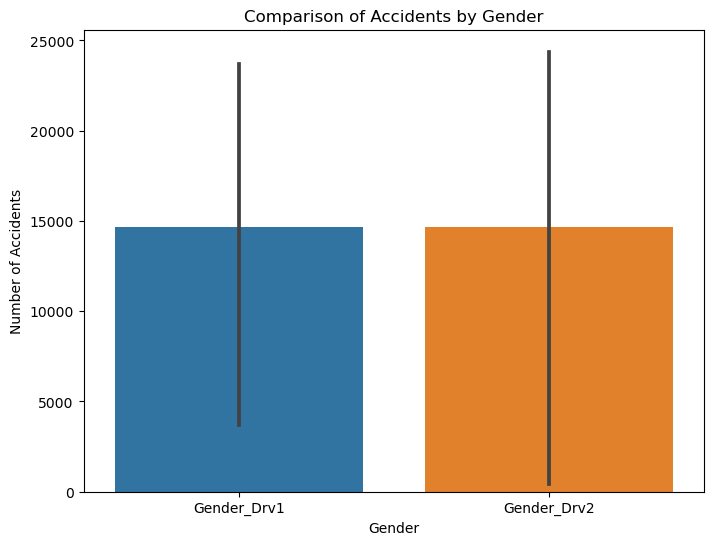

In [39]:
gender_counts = pd.concat([filtered_data['Gender_Drv1'].value_counts(),
                           filtered_data['Gender_Drv2'].value_counts()], axis=1)
gender_counts.columns = ['Gender_Drv1', 'Gender_Drv2']

# Create a bar plot to compare the frequencies
plt.figure(figsize=(8, 6))
sns.barplot(data=gender_counts)
plt.xlabel('Gender')
plt.ylabel('Number of Accidents')
plt.title('Comparison of Accidents by Gender')
plt.show()


# 1.Now count the number of accidents by 'Gender_Drv2':

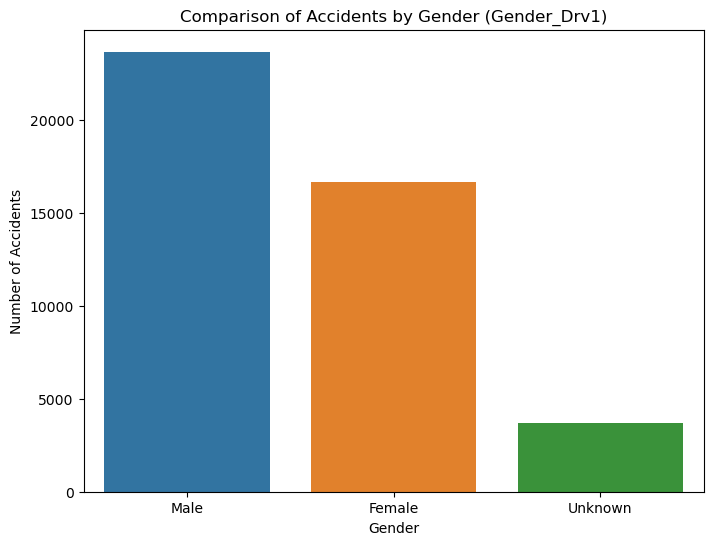

In [40]:
gender_counts = cd['Gender_Drv1'].value_counts()

# Create a bar plot to compare the frequencies
plt.figure(figsize=(8, 6))
sns.barplot(x=gender_counts.index, y=gender_counts.values)
plt.xlabel('Gender')
plt.ylabel('Number of Accidents')
plt.title('Comparison of Accidents by Gender (Gender_Drv1)')
plt.show()


# 2.Now count the number of accidents by 'Gender_Drv2':

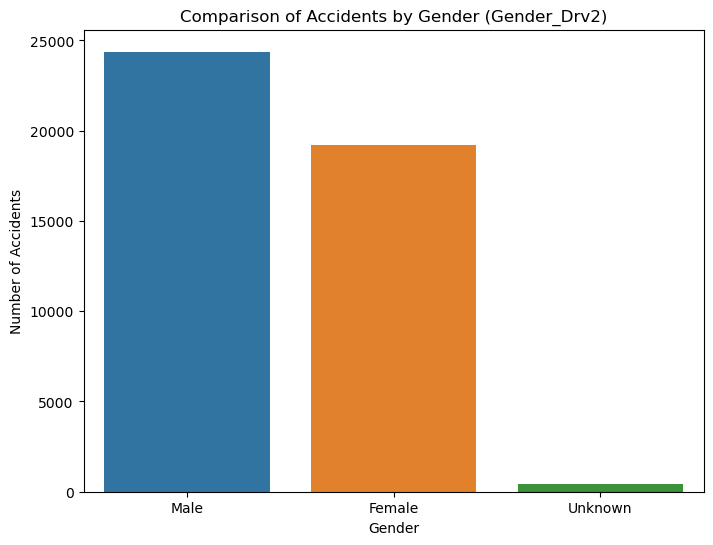

In [41]:

gender_counts = cd['Gender_Drv2'].value_counts()

# Create a bar plot to compare the frequencies
plt.figure(figsize=(8, 6))
sns.barplot(x=gender_counts.index, y=gender_counts.values)
plt.xlabel('Gender')
plt.ylabel('Number of Accidents')
plt.title('Comparison of Accidents by Gender (Gender_Drv2)')
plt.show()


# Filter the dataset to include accidents involving individuals aged 50

In [42]:

cd = cd[(cd['Age_Drv1'] >50) | (cd['Age_Drv2'] < 50)]

# Display the filtered dataset
cd.head().transpose()


,0,1,6,7,8
DateTime,2012/01/10 05:55:00+00,2012/01/10 14:55:00+00,2012/01/10 20:04:00+00,2012/01/01 07:25:00+00,2012/01/10 20:40:00+00
Year,2012,2012,2012,2012,2012
StreetName,Rural Rd,Mcclintock Dr,Priest Dr,University Dr,Mill Ave
CrossStreet,University Dr,State Route 202 Exit 8 A-Ramp,3rd St,Hardy Dr,Broadmor Dr
Distance,0.0,-533.808,0.0,0.0,96.096
JunctionRelation,Not Junction Related,Intersection Related Non Interchange,Intersection Non Interchange,Intersection Non Interchange,Intersection Related Non Interchange
Totalinjuries,0.0,3.0,0.0,6.0,0.0
Totalfatalities,0.0,0.0,0.0,0.0,0.0
Injuryseverity,No Injury,Non Incapacitating Injury,No Injury,Non Incapacitating Injury,No Injury
Collisionmanner,ANGLE (Front To Side)(Other Than Left Turn),Rear End,ANGLE (Front To Side)(Other Than Left Turn),ANGLE (Front To Side)(Other Than Left Turn),Rear End


# Count the accidents for each unique 'JunctionRelation' value for both drivers

In [43]:
# Filter the dataset to include relevant columns
filtered_data = cd[['JunctionRelation', 'Gender_Drv1', 'Gender_Drv2', 'Age_Drv1', 'Age_Drv2']]
accident_counts = filtered_data.groupby('JunctionRelation')[['Gender_Drv1', 'Gender_Drv2']].count()



# Determine which driver had the highest count of accidents near the junction relation

In [44]:
driver_with_most_accidents = accident_counts.sum(axis=1).idxmax()
print(f"The driver with the most accidents near the junction relation is: {driver_with_most_accidents}")


The driver with the most accidents near the junction relation is: Not Junction Related


# which gender had the highest count of accidents near the junction relation:

In [45]:
# Filter the dataset to include relevant columns
filtered_data = cd[['JunctionRelation', 'Gender_Drv1', 'Gender_Drv2']]
# Calculate the count of accidents for each unique 'JunctionRelation' value, separately for male and female drivers
male_counts = filtered_data[filtered_data['Gender_Drv1'] == 'Male']['JunctionRelation'].value_counts()
female_counts = filtered_data[filtered_data['Gender_Drv1'] == 'Female']['JunctionRelation'].value_counts()


if male_counts.sum() > female_counts.sum():
    driver_with_most_accidents = 'Male'
else:
    driver_with_most_accidents = 'Female'

print(f"The driver (male or female) with the most accidents near the junction relation is: {driver_with_most_accidents}")


The driver (male or female) with the most accidents near the junction relation is: Male


# Calculate the count of accidents for each unique 'Age_Drv1' and 'Age_Drv2' value, considering only male drivers, also  Find the age(s) with the highest count of accidents near the junction relation for male drivers:

In [46]:
# Filter the dataset to include relevant columns
filtered_data = cd[['JunctionRelation', 'Age_Drv1', 'Age_Drv2', 'Gender_Drv1', 'Gender_Drv2']]

# Filter the data to include only male drivers
male_data = filtered_data[(filtered_data['Gender_Drv1'] == 'Male') | (filtered_data['Gender_Drv2'] == 'Male')]


male_age_counts = male_data['Age_Drv1'].value_counts().add(male_data['Age_Drv2'].value_counts(), fill_value=0)


max_accidents_age = male_age_counts.idxmax()

print(f"The age(s) with the most accidents near the junction relation for male drivers is: {max_accidents_age}")


The age(s) with the most accidents near the junction relation for male drivers is: 21.0


In [47]:
cd.to_csv('108-crash-data-report.csv')